
<div class="alert alert-block alert-success">
<b> Ex - 4 : </b>  Develop an image segmentation model using a fully convolutional network.

<hr style="border-top: 3px dotted #bbb;">


# Procedure
- ### Load the data
- ### Image and mask data generators
- ### Combine generators into one which yields image and maskl
- ### Build The Fully Convolutional Neural Network
- ### Train the FCNN model
- ### Fit the model with the custom generator
- ### Sample image for prediction

<details>
<summary><b>👉 Click here to reveal the hidden code solution</b></summary>

```python
# Your hidden code block sits neatly inside here
import tensorflow as tf
print("Hidden code executed!")
```
</details>


---
## 1. Import necessary Libraries

In [2]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator

## 2 : Load the Dataset

In [ ]:
# Paths to images and masks directories
image_path = r'E:\Z_Arise\DL\Ex_4_Develop_an_image_segmentation_model\Banana FCN\Images'
mask_path = r'E:\Z_Arise\DL\Ex_4_Develop_an_image_segmentation_model\Banana FCN\Mask'

image_dir = image_path # "image path"
mask_dir = mask_path # "mask path"




##  Image and mask data generators

In [ ]:
# Image and mask data generators
image_datagen = ImageDataGenerator(rescale=1./255)
mask_datagen = ImageDataGenerator(rescale=1./255)

image_generator = image_datagen.flow_from_directory(
    image_dir,
    class_mode=None,
    color_mode='rgb',
    target_size=(128, 128),
    batch_size=32,
    seed=42,
    shuffle = False

)

mask_generator = mask_datagen.flow_from_directory(
    mask_dir,
    class_mode=None,
    color_mode='grayscale',
    target_size=(128, 128),
    batch_size=32,
    seed=42
)

Found 82 images belonging to 1 classes.
Found 82 images belonging to 1 classes.


## 2.1 Combine generators into one which yields image and mask

In [20]:
# Combine generators into one which yields image and mask
train_generator = zip(image_generator, mask_generator)


from tensorflow.keras.layers import Conv2D, MaxPooling2D, Conv2DTranspose, Input
from tensorflow.keras.models import Model

## 2.2 Build a FCNN

In [21]:
def build_FCNN():
    inputs = Input((128, 128, 3))

    # Encoder
    conv1 = Conv2D(128, (3, 3), activation='relu', padding='same')(inputs)
    pool1 = MaxPooling2D((2, 2))(conv1)

    conv2 = Conv2D(256, (3, 3), activation='relu', padding='same')(pool1)
    pool2 = MaxPooling2D((2, 2))(conv2)

    # Decoder
    conv3 = Conv2D(256, (3, 3), activation='relu', padding='same')(pool2)
    up1 = Conv2DTranspose(128, (2, 2), strides=(2, 2), padding='same')(conv3)

    conv4 = Conv2D(128, (3, 3), activation='relu', padding='same')(up1)
    up2 = Conv2DTranspose(64, (2, 2), strides=(2, 2), padding='same')(conv4)

    outputs = Conv2D(1, (1, 1), activation='sigmoid', padding='same')(up2)

    model = Model(inputs, outputs)
    return model

## 3  Build the model

In [22]:
model = build_FCNN()
model.compile(
    optimizer = 'adam',
    loss = 'binary_crossentropy',
    metrics = ['accuracy']
)

model.summary()


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 128, 128, 128)  │         3,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 64, 64, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 64, 64, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 32, 32, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 32, 32, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_2              │ (None, 64, 64, 128)    │       131,200 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 64, 64, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_3              │ (None, 128, 128, 64)   │        32,832 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 128, 128, 1)    │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,200,513 (4.58 MB)

 Trainable params: 1,200,513 (4.58 MB)

 Non-trainable params: 0 (0.00 B)

In [23]:
# Train the FCNN model
def combined_generator(image_gen, mask_gen):
    while True:  # Keep yielding data indefinitely
        img_batch = next(image_gen)
        mask_batch = next(mask_gen)
        yield img_batch, mask_batch  # Keras expects (input, target)
# Fit the model with the custom generator
train_generator = combined_generator(image_generator, mask_generator)
model.fit(train_generator, steps_per_epoch=len(image_generator), epochs=50)

e:\Z_Arise\rika_dl_env\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a generator. The generator is expected to yield already-shuffled data.
  self.data_adapter = data_adapters.get_data_adapter(


Epoch 1/50
3/3 ━━━━━━━━━━━━━━━━━━━━ 11s 3s/step - accuracy: 0.5032 - loss: 0.6677
Epoch 2/50
3/3 ━━━━━━━━━━━━━━━━━━━━ 10s 3s/step - accuracy: 0.6847 - loss: 0.6156
Epoch 3/50
3/3 ━━━━━━━━━━━━━━━━━━━━ 8s 2s/step - accuracy: 0.6847 - loss: 0.5965
Epoch 4/50
3/3 ━━━━━━━━━━━━━━━━━━━━ 10s 3s/step - accuracy: 0.6847 - loss: 0.5652
Epoch 5/50
3/3 ━━━━━━━━━━━━━━━━━━━━ 9s 3s/step - accuracy: 0.6847 - loss: 0.5426
Epoch 6/50
3/3 ━━━━━━━━━━━━━━━━━━━━ 9s 3s/step - accuracy: 0.6847 - loss: 0.5452
Epoch 7/50
3/3 ━━━━━━━━━━━━━━━━━━━━ 7s 2s/step - accuracy: 0.6847 - loss: 0.5393
Epoch 8/50
3/3 ━━━━━━━━━━━━━━━━━━━━ 7s 2s/step - accuracy: 0.6847 - loss: 0.5451
Epoch 9/50
3/3 ━━━━━━━━━━━━━━━━━━━━ 8s 2s/step - accuracy: 0.6847 - loss: 0.5349
Epoch 10/50
3/3 ━━━━━━━━━━━━━━━━━━━━ 8s 2s/step - accuracy: 0.6847 - loss: 0.5221
Epoch 11/50
3/3 ━━━━━━━━━━━━━━━━━━━━ 7s 2s/step - accuracy: 0.6847 - loss: 0.5178
Epoch 12/50
3/3 ━━━━━━━━━━━━━━━━━━━━ 7s 2s/step - accuracy: 0.6665 - loss: 0.5196
Epoch 13/50
3/3 ━━━━━━

## Sample image for prediction

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 78ms/step


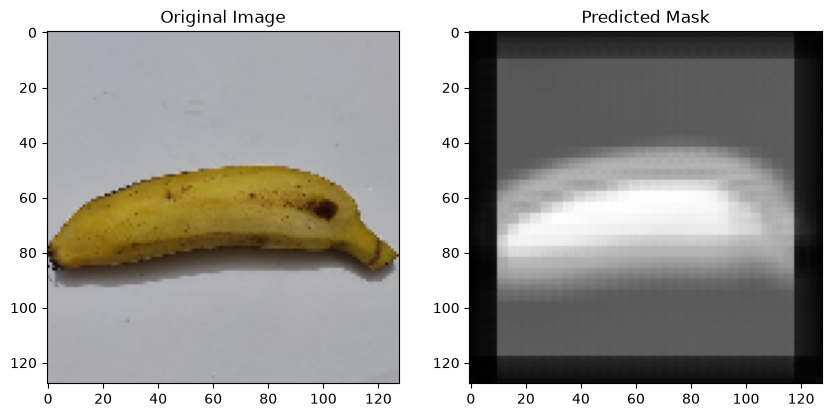

In [51]:

import matplotlib.pyplot as plt
import numpy as np
import random as rand

# Sample image for prediction
# i = rand.randint(0,7)
# j = rand.randint(0,2)
# sample_image = image_generator[i][j]
# Get one random batch
batch_images = next(image_generator)          # shape: (batch_size, 128, 128, 3)

# Pick a random image from that batch
idx = rand.randint(0, batch_images.shape[0] - 1)
sample_image = batch_images[idx]

predicted_mask = model.predict(np.expand_dims(sample_image, axis=0))[0]

# Display the original image and predicted mask
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.title("Original Image")
plt.imshow(sample_image)

plt.subplot(1, 2, 2)
plt.title("Predicted Mask")
plt.imshow(predicted_mask.squeeze(), cmap='gray')

plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 503ms/step


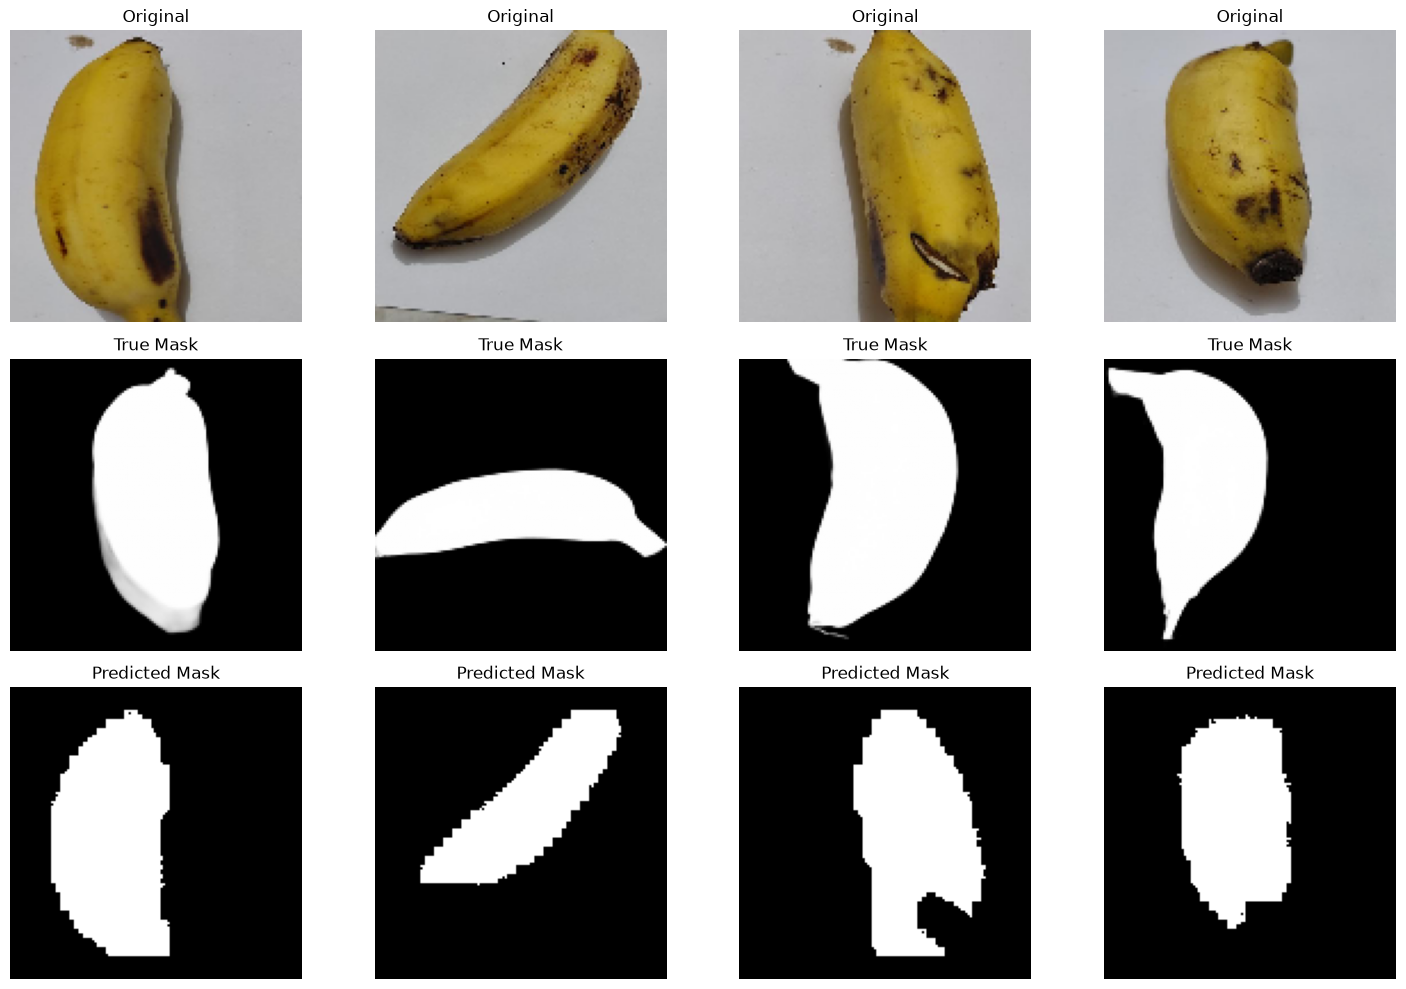

In [48]:


import matplotlib.pyplot as plt
import numpy as np

# Get a batch
images, masks = next(train_generator)

# Predict
preds = model.predict(images)

# Show 4 samples
plt.figure(figsize=(15, 10))

for i in range(4):
    # Original Image
    plt.subplot(3, 4, i+1)
    plt.imshow(images[i])
    plt.title("Original")
    plt.axis('off')

    # Ground Truth Mask
    plt.subplot(3, 4, i+5)
    plt.imshow(masks[i].squeeze(), cmap='gray')
    plt.title("True Mask")
    plt.axis('off')

    # Predicted Mask
    plt.subplot(3, 4, i+9)
    plt.imshow(preds[i].squeeze() > 0.5, cmap='gray')  # threshold
    plt.title("Predicted Mask")
    plt.axis('off')

plt.tight_layout()
plt.show()
